# Module 7B — ปรับกราฟและส่งออกให้พร้อมใช้

**เป้าหมาย:** เปลี่ยน default plot เป็นภาพที่มี visual hierarchy, uncertainty, annotation และขนาดส่งออก
ที่เหมาะกับ paper/slide/web แล้วพิจารณา interaction เฉพาะเมื่อมีงานให้ทำ

## ที่มาและขอบเขต

โครงเรื่องยึดแกนการสอนจากสไลด์ Data Visualization ของ Research Track I แล้วสร้างตัวอย่างใหม่
และเติมหลักการจาก corpus หนังสือภายใน ดู locator ที่
[source map](module-07-data-visualization-source-map.md)

แหล่งหลัก: `[KIERAN-HEALY, pdf pp. 12–16, 22–32, 43–50]`,
`[HANDBOOK, pdf pp. 69–90, 229–247]`, `[DV-EBOOK, pdf pp. 18–19]`

เนื้อหานี้ไม่ทดแทนวิชาสถิติหรือระเบียบวิธีวิจัย กราฟที่ดูสมเหตุสมผลอาจยังตั้งอยู่บน
model, sampling หรือ causal claim ที่ผิดได้

## 0. เครื่องมือฟรีที่ใช้

Notebook นี้เป็นแบบ standalone เซลล์ setup ถัดไปจะตรวจทั้งการมีอยู่และรุ่นของ package
แล้วติดตั้ง core stack ที่ขาดหรือเก่าเกินไปให้ครบใน Python environment ของ kernel ปัจจุบัน
จึงไม่สมมติว่าเครื่องเคยติดตั้ง package จากบทก่อนหน้า

| งาน | ไลบรารี | เหตุผลที่อยู่ในคลาส |
|---|---|---|
| ภาพนิ่งและควบคุมรายละเอียด | Matplotlib | เป็นฐานที่กว้างและส่งออก SVG/PDF ได้ |
| distribution/statistical graphics | Seaborn | ทำ layer ของ raw points, violin, interval ได้เร็ว |
| hover/zoom/filter | Plotly Express | สร้าง interactive HTML แบบ standalone ได้ |
| linked views/brushing | Altair | grammar ชัด เหมาะกับการอธิบาย encoding และ interaction |

ไลบรารีไม่ใช่ผู้ตัดสินความถูกต้อง—มันเพียงทำตามข้อมูลและ parameter ที่ได้รับ

### เครื่องมืออื่นที่ควรรู้จัก

คลาสนี้ไม่จำเป็นต้องติดตั้งทุกตัว แต่ควรรู้ว่ามีทางเลือกสำหรับงานเฉพาะทาง:

- [deck.gl](https://deckgl.readthedocs.io/en/latest/) — เหมาะกับแผนที่หรือข้อมูลเชิงพื้นที่
  ปริมาณมากที่ต้องใช้การเร่งผลด้วย WebGL
- [Lets-Plot](https://lets-plot.org/) — แนว grammar of graphics สำหรับสร้างภาพนิ่งและ
  interactive plot โดยเขียน specification เป็นระบบ
- [Folium](https://python-visualization.github.io/folium/latest/) — ใช้ Python สร้างแผนที่
  interactive บนฐาน Leaflet เหมาะกับ marker, polygon, choropleth และ layer control

ทั้งสามตัวเป็น **ทางเลือกตามโจทย์** ไม่ใช่รายการ package ที่ทุกคนต้องมี หากคำถามวิจัยไม่มีมิติ
เชิงพื้นที่ การเพิ่มแผนที่อาจทำให้ซับซ้อนขึ้นโดยไม่ได้เพิ่มคำตอบ

ขั้นตอน Colab, Prompt และ workflow อยู่ใน
[Module 7 Workflow & Prompt Card](../templates/module-07-visualization-workflow-and-prompts.md)

In [1]:
# Standalone bootstrap for a fresh local environment or Google Colab.
# It checks package versions, then installs every missing/incompatible core dependency.
from importlib import invalidate_caches
from importlib.metadata import PackageNotFoundError, version
import subprocess
import sys

def ensure_packaging():
    try:
        from packaging.specifiers import SpecifierSet
        return SpecifierSet
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip", "install",
            "--disable-pip-version-check", "--quiet", "packaging>=24,<27",
        ])
        invalidate_caches()
        from packaging.specifiers import SpecifierSet
        return SpecifierSet

SpecifierSet = ensure_packaging()
required = {
    "numpy": ">=1.26,<3",
    "pandas": ">=2.1,<3",
    "matplotlib": ">=3.8,<4",
    "seaborn": ">=0.13,<0.14",
    "plotly": ">=5.20,<8",
    "altair": ">=5.2,<7",
}
to_install = []
for distribution, constraint in required.items():
    try:
        installed = version(distribution)
    except PackageNotFoundError:
        installed = None
    if installed is None or installed not in SpecifierSet(constraint):
        to_install.append(f"{distribution}{constraint}")

if to_install:
    print("Installing Module 7 core packages:", ", ".join(to_install))
    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "--disable-pip-version-check", "--upgrade-strategy", "only-if-needed",
        *to_install,
    ])
    invalidate_caches()
else:
    print("Module 7 core packages already satisfy the supported versions.")

verified = {name: version(name) for name in required}
print("Python:", sys.executable)
print("Verified:", verified)

Module 7 core packages already satisfy the supported versions.
Python: [current kernel]
Verified: {'numpy': '2.2.6', 'pandas': '2.3.3', 'matplotlib': '3.10.8', 'seaborn': '0.13.2', 'plotly': '7.0.0', 'altair': '6.2.2'}


In [2]:
import sys
from pathlib import Path

import altair as alt
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly
import plotly.express as px
import plotly.io as pio
import seaborn as sns

SEED = 20261110
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({"figure.dpi": 120, "axes.titleweight": "bold"})
alt.data_transformers.disable_max_rows()
pio.renderers.default = "notebook"

versions = pd.Series({
    "python": sys.version.split()[0],
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": mpl.__version__,
    "seaborn": sns.__version__,
    "plotly": plotly.__version__,
    "altair": alt.__version__,
}, name="version")
versions.to_frame()

,version
python,3.10.19
pandas,2.3.3
numpy,2.2.6
matplotlib,3.10.8
seaborn,0.13.2
plotly,7.0.0
altair,6.2.2


In [3]:
# Teaching data 1: three groups with exactly the same sample mean and SD.
n = 60
raw_shapes = {
    "Near-normal": rng.normal(size=n),
    "Bimodal": np.r_[rng.normal(-2.2, 0.35, n // 2), rng.normal(2.2, 0.35, n // 2)],
    "One outlier": np.r_[rng.normal(0, 0.25, n - 1), 8.0],
}

def same_summary(x, mean=50, sd=10):
    x = np.asarray(x, dtype=float)
    return mean + sd * (x - x.mean()) / x.std(ddof=1)

shape_df = pd.concat(
    [pd.DataFrame({"group": name, "value": same_summary(values)})
     for name, values in raw_shapes.items()],
    ignore_index=True,
)

# Teaching data 2: repeated sensor-calibration runs for the makeover.
methods = ["Baseline", "Robust fit", "Proposed"]
minutes = np.arange(0, 61, 5)
rows = []
for method in methods:
    for run in range(1, 25):
        humidity = rng.uniform(35, 85)
        for minute in minutes:
            base = {"Baseline": 8.0, "Robust fit": 6.4, "Proposed": 5.8}[method]
            decay = {"Baseline": 0.030, "Robust fit": 0.043, "Proposed": 0.060}[method]
            floor = {"Baseline": 2.7, "Robust fit": 2.0, "Proposed": 1.5}[method]
            drift = max(humidity - 65, 0) * {"Baseline": .045, "Robust fit": .025, "Proposed": .012}[method]
            error = floor + base * np.exp(-decay * minute) + drift + rng.normal(0, .55)
            rows.append((method, run, minute, humidity, max(error, .15)))
sensor_df = pd.DataFrame(rows, columns=["method", "run", "minute", "humidity", "error_ppm"])

assert np.allclose(shape_df.groupby("group")["value"].mean(), 50)
assert np.allclose(shape_df.groupby("group")["value"].std(), 10)
assert not sensor_df.isna().any().any()
print(f"shape_df: {shape_df.shape}; sensor_df: {sensor_df.shape}; seed={SEED}")

shape_df: (180, 2); sensor_df: (936, 5); seed=20261110


## เตรียมตารางสำหรับสร้างภาพ

Part B ใช้ repeated sensor runs ชุดเดียวกับ Part A แต่รวมเป็น median และช่วง 25–75% ก่อนเริ่ม makeover
ตารางนี้คือหลักฐานตรงที่ต้องส่งคู่กับกราฟ ไม่ให้ plotting library รวมค่าโดยไม่บอกเรา

> **ที่มาหลัก:** `[KIERAN-HEALY, pdf pp. 101–112, 125–129]`; `[RT1-DATAVIZ, pdf pp. 42–49]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

In [4]:
plot_df = (
    sensor_df.groupby(["method", "minute"])["error_ppm"]
    .agg(median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75), n="size")
    .reset_index()
)
palette = {"Baseline": "#777777", "Robust fit": "#4C78A8", "Proposed": "#D04A35"}
assert (plot_df["q25"] <= plot_df["median"]).all()
assert (plot_df["median"] <= plot_df["q75"]).all()
plot_df.head()

,method,minute,median,q25,q75,n
0,Baseline,0,10.711111,10.369762,11.307295,24
1,Baseline,5,9.863469,9.349310,10.468478,24
2,Baseline,10,8.782864,8.357807,9.465177,24
3,Baseline,15,8.011802,7.643048,8.509643,24
4,Baseline,20,7.110991,6.453394,7.687182,24


## 1. Makeover — จาก default plot สู่ภาพพร้อมใช้ใน paper

กรณีจำลอง: เปรียบเทียบ absolute calibration error ของ 3 วิธี จาก repeated runs ตลอด 60 นาที
เป้าหมายไม่ใช่ “ทำให้สวย” แต่ทำให้ข้อค้นพบตรวจได้และไม่ซ่อนความแปรปรวน

> **ที่มาหลัก:** `[KIERAN-HEALY, pdf pp. 22–32]`; `[HANDBOOK, pdf pp. 69–90]`; `[RT1-DATAVIZ, pdf pp. 42–50]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

### Draft 0 — วาดทุกเส้นก่อน

การแสดง run ทุกเส้นช่วยยืนยันว่าข้อมูลมีความแปรปรวนจริง แต่เมื่อทุกเส้นมีน้ำหนักเท่ากัน ผู้อ่านจะตาม
pattern หลักได้ยาก กราฟนี้จึงเป็นร่างสำรวจ ไม่ใช่ภาพสุดท้ายสำหรับบทความ

> **ที่มาหลัก:** `[RT1-DATAVIZ, pdf pp. 42–43]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

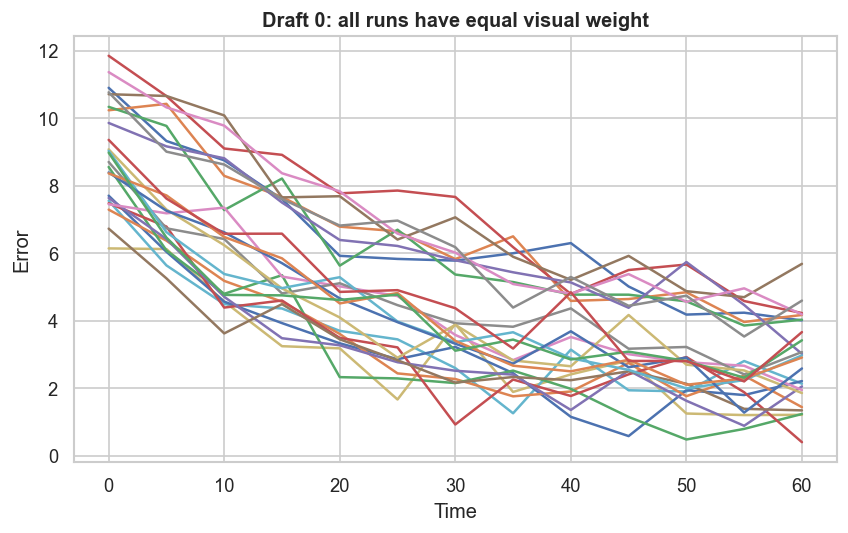

In [5]:
# Draft 0: every run, default styling, no explanation of the visual hierarchy.
sample_runs = sensor_df.query("run <= 8")
fig, ax = plt.subplots(figsize=(8.2, 4.6))
for (_, _), part in sample_runs.groupby(["method", "run"]):
    ax.plot(part["minute"], part["error_ppm"])
ax.set_title("Draft 0: all runs have equal visual weight")
ax.set_xlabel("Time")
ax.set_ylabel("Error")
plt.show()

**Audit Draft 0:** หน่วยไม่ครบ, legend ใช้ไม่ได้, สีไม่มีความหมาย, เส้นดิบแย่งความสนใจ,
และยังไม่บอกว่าเส้นสรุปจะใช้ mean/median หรือ uncertainty แบบใด

การแก้เริ่มจากสร้าง `plot_df` ที่ตรวจได้ ไม่ใช่เริ่มจาก theme

> **ที่มาหลัก:** `[RT1-DATAVIZ, pdf pp. 43–44]`; `[KIERAN-HEALY, pdf pp. 22–32]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

In [6]:
# Verify the exact table feeding the chart.
checks = pd.DataFrame({
    "rows": [len(plot_df)],
    "methods": [plot_df["method"].nunique()],
    "time_points_per_method": [plot_df.groupby("method")["minute"].nunique().min()],
    "runs_per_cell_min": [plot_df["n"].min()],
    "q25_le_median": [(plot_df["q25"] <= plot_df["median"]).all()],
    "median_le_q75": [(plot_df["median"] <= plot_df["q75"]).all()],
})
checks

,rows,methods,time_points_per_method,runs_per_cell_min,q25_le_median,median_le_q75
0,39,3,13,24,True,True


### Draft 1 — สรุปโดยยังรักษาความแปรปรวน

หลังตรวจ `plot_df` แล้ว เราใช้ median เป็นเส้นกลาง ใช้ IQR เป็นแถบเงา ระบุหน่วยและจำนวน runs
และเน้น Proposed เพียง series เดียว จุดสำคัญคือทุกองค์ประกอบมีความหมายที่อธิบายได้

> **ที่มาหลัก:** `[RT1-DATAVIZ, pdf pp. 44–46]`; `[KIERAN-HEALY, pdf pp. 154, 186–188]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

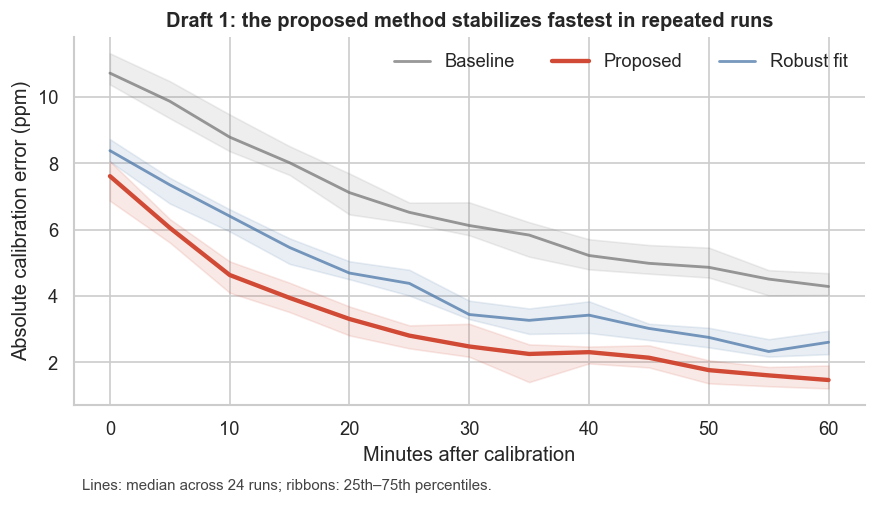

In [7]:
# Draft 1: shared scale, explicit units, median + IQR, one purposeful highlight.
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for method, part in plot_df.groupby("method", sort=False):
    color = palette[method]
    ax.fill_between(part["minute"], part["q25"], part["q75"], color=color, alpha=.12)
    ax.plot(part["minute"], part["median"], color=color,
            lw=2.6 if method == "Proposed" else 1.7,
            alpha=1 if method == "Proposed" else .75, label=method)
ax.set(title="Draft 1: the proposed method stabilizes fastest in repeated runs",
       xlabel="Minutes after calibration", ylabel="Absolute calibration error (ppm)")
ax.text(.01, -.23, "Lines: median across 24 runs; ribbons: 25th–75th percentiles.",
        transform=ax.transAxes, fontsize=9, color="#444")
ax.legend(frameon=False, ncol=3)
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(bottom=.24)
plt.show()

### Draft 2 — ให้ชื่อภาพและ annotation ทำงานร่วมกับหลักฐาน

รุ่นสุดท้ายตัด legend ออกแล้วติดชื่อที่ปลายเส้น เพิ่ม threshold ซึ่งมีความหมายเชิงปฏิบัติการ
และใช้ชื่อภาพที่กล่าวเฉพาะข้อค้นพบที่ข้อมูลรองรับ การเพิ่ม annotation ต้องไม่ขยายไปเป็นข้ออ้างเชิงเหตุผล

> **ที่มาหลัก:** `[RT1-DATAVIZ, pdf pp. 47–49]`; `[HANDBOOK, pdf pp. 69–90]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

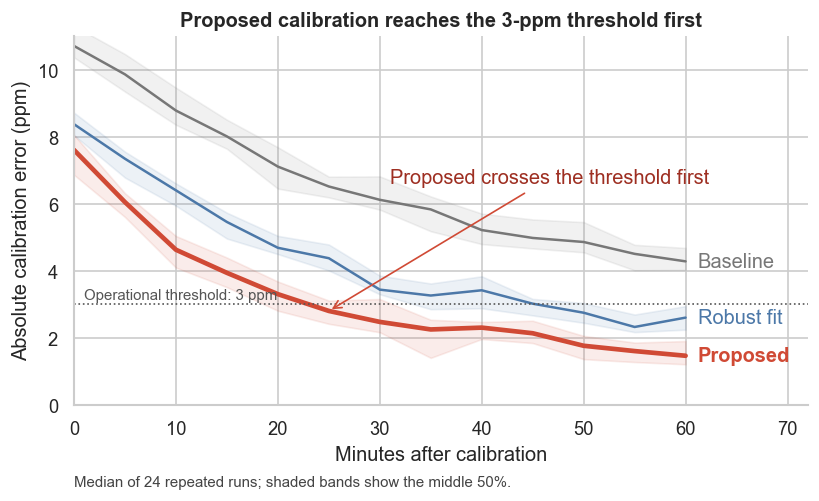

In [8]:
# Draft 2: direct labels and an annotation tied to a defensible threshold.
fig, ax = plt.subplots(figsize=(8.8, 4.8))
for method, part in plot_df.groupby("method", sort=False):
    color = palette[method]
    ax.fill_between(part["minute"], part["q25"], part["q75"], color=color, alpha=.10)
    ax.plot(part["minute"], part["median"], color=color,
            lw=2.8 if method == "Proposed" else 1.5)
    last = part.iloc[-1]
    ax.text(last["minute"] + 1.2, last["median"], method,
            va="center", color=color, weight="bold" if method == "Proposed" else "normal")

threshold = 3.0
ax.axhline(threshold, color="#555", lw=1, ls=":")
ax.text(1, threshold + .15, "Operational threshold: 3 ppm", color="#555", fontsize=9)
ax.annotate("Proposed crosses the threshold first",
            xy=(25, plot_df.query("method == 'Proposed' and minute == 25")["median"].iloc[0]),
            xytext=(31, 6.6), arrowprops={"arrowstyle": "->", "color": "#D04A35"},
            color="#9E2F22")
ax.set_xlim(0, 72)
ax.set_ylim(0, 11)
ax.set(title="Proposed calibration reaches the 3-ppm threshold first",
       xlabel="Minutes after calibration", ylabel="Absolute calibration error (ppm)")
ax.text(.0, -.22, "Median of 24 repeated runs; shaded bands show the middle 50%.",
        transform=ax.transAxes, fontsize=9, color="#444")
ax.spines[["top", "right"]].set_visible(False)
fig.subplots_adjust(bottom=.24, right=.82)
plt.show()

**ตรวจ claim อีกครั้ง:** ชื่อภาพ Draft 2 กล่าวเฉพาะสิ่งที่กราฟรองรับ—เวลาในการผ่าน threshold
ภายใต้ข้อมูลจำลองนี้ ไม่ได้กล่าวว่าวิธี Proposed “ดีที่สุดทุกด้าน” หรือมี causal mechanism ใด

> **ที่มาหลัก:** `[KIERAN-HEALY, pdf pp. 22–32]`; `[HANDBOOK, pdf pp. 69–90]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

### ทดสอบภาพที่ขนาดใช้งานจริงและเมื่อฉาย

กราฟที่อ่านได้บนจอผู้สร้างอาจอ่านไม่ออกเมื่อย่อเป็นหนึ่งคอลัมน์หรือฉายจากท้ายห้อง ให้ตรวจ font, contrast,
จำนวน series และความหนาเส้นที่ขนาดจริง โดยไม่แก้ด้วยการเพิ่มทุกอย่างให้ใหญ่จนไม่มีพื้นที่ข้อมูล

> **ที่มาหลัก:** `[RT1-DATAVIZ, pdf p. 36]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

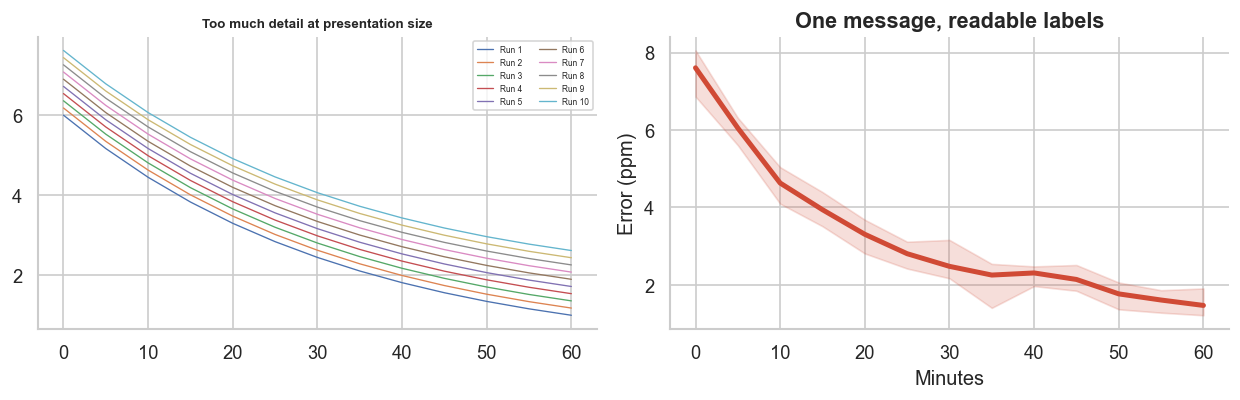

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5))
for i in range(10):
    axes[0].plot(minutes, 6*np.exp(-.03*minutes) + i*.18, lw=.8, label=f"Run {i+1}")
axes[0].legend(fontsize=5, ncol=2); axes[0].set_title("Too much detail at presentation size", fontsize=8)
proposed = plot_df.query("method == 'Proposed'")
axes[1].plot(proposed["minute"], proposed["median"], color="#D04A35", lw=3)
axes[1].fill_between(proposed["minute"], proposed["q25"], proposed["q75"], color="#D04A35", alpha=.18)
axes[1].set_title("One message, readable labels", fontsize=13)
axes[1].set(xlabel="Minutes", ylabel="Error (ppm)")
for ax in axes: ax.spines[["top","right"]].set_visible(False)
fig.tight_layout(); plt.show()

### ทำภาพขนาดหนึ่งคอลัมน์และส่งออก vector

กำหนดขนาดก่อนออกแบบ ไม่ใช่สร้างภาพใหญ่แล้วปล่อยให้โปรแกรมเอกสารย่อเอง ตัวอย่างนี้ใช้ 3.5 × 2.4 นิ้ว,
font 8 pt และ PDF font type 42 เพื่อคงข้อความเป็น font ที่แก้ไข/ค้นได้ การเขียนไฟล์ปิดไว้เป็นค่าเริ่มต้น

> **ที่มาหลัก:** `[HANDBOOK, pdf pp. 744, 773–776]`; `[RT1-DATAVIZ, pdf p. 50]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

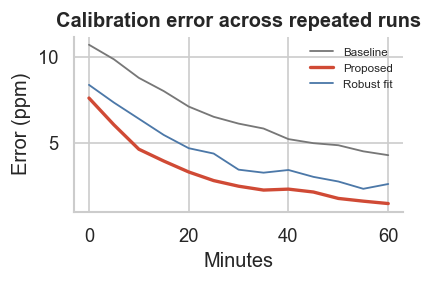

In [10]:
PAPER_EXPORT = False
with mpl.rc_context({"font.size": 8, "pdf.fonttype": 42, "ps.fonttype": 42}):
    paper_fig, paper_ax = plt.subplots(figsize=(3.5, 2.4))
    for method, part in plot_df.groupby("method", sort=False):
        paper_ax.plot(part["minute"], part["median"], color=palette[method],
                      lw=2 if method == "Proposed" else 1.1, label=method)
    paper_ax.set(xlabel="Minutes", ylabel="Error (ppm)", title="Calibration error across repeated runs")
    paper_ax.spines[["top","right"]].set_visible(False)
    paper_ax.legend(frameon=False, fontsize=7)
    paper_fig.tight_layout()
    if PAPER_EXPORT:
        Path("module07_outputs").mkdir(exist_ok=True)
        paper_fig.savefig("module07_outputs/figure-one-column.pdf", bbox_inches="tight")
        paper_fig.savefig("module07_outputs/figure-one-column.svg", bbox_inches="tight")
    plt.show()

## 2. กราฟที่ไม่ใช่ default ทั่วไป

อย่าใช้เพราะดูแปลกใหม่ ให้ใช้เมื่อช่วยงานอ่านค่า:

- **Dumbbell/slope:** paired before–after โดยรักษาคู่ข้อมูล
- **Forest/interval plot:** estimate พร้อม uncertainty และ reference
- **Hexbin:** ลด overplotting ใน scatter ที่มีจุดหนาแน่น
- **Small multiples:** เปรียบเทียบรูปแบบซ้ำ ๆ บน scale ร่วม
- **ECDF:** เห็น distribution ทั้งช่วงโดยไม่ขึ้นกับ bin width

> **ที่มาหลัก:** `[KIERAN-HEALY, pdf pp. 101–129]`; `[HANDBOOK, pdf pp. 84–85]`; `[RT1-DATAVIZ, pdf p. 51]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

### เลือกกราฟพิเศษจากงานอ่านค่า ไม่ใช่จากความแปลก

ภาพถัดไปเปรียบเทียบสามโจทย์: dumbbell รักษาคู่ before–after, forest plot วางค่าประมาณกับช่วง
ความไม่แน่นอน และ hexbin รวมจุดที่ซ้อนกันหนาแน่นเป็นจำนวนในแต่ละช่อง รูปแบบเหล่านี้มีประโยชน์
เมื่อแก้ปัญหาของข้อมูลจริง ไม่ใช่เพราะดูซับซ้อนกว่า bar chart

> **ที่มาหลัก:** `[KIERAN-HEALY, pdf pp. 101–129]`; `[HANDBOOK, pdf pp. 84–85]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

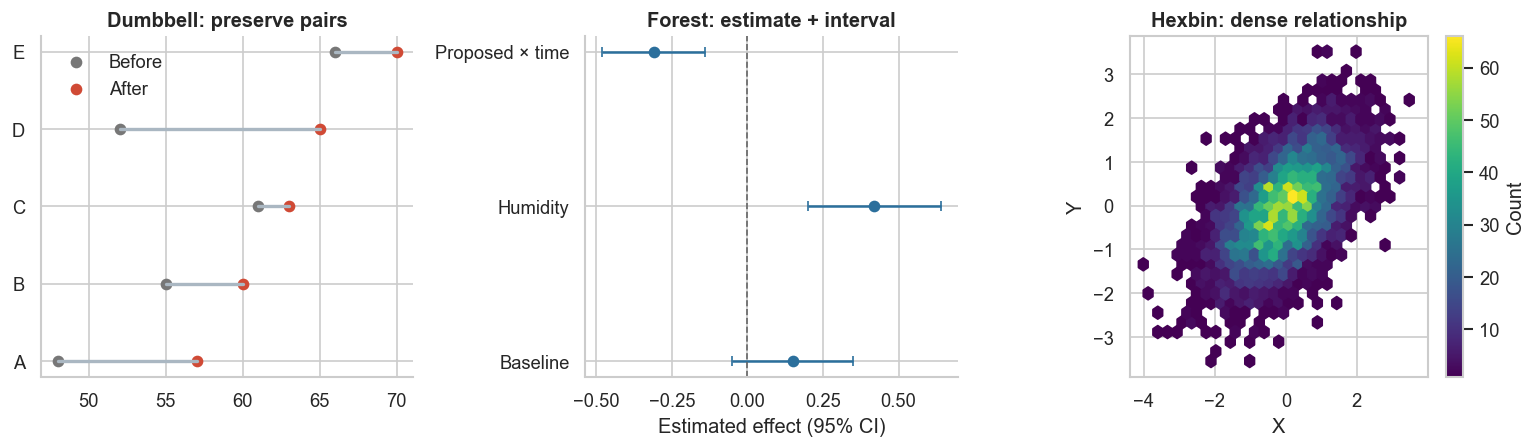

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))

# Dumbbell
cohorts = ["A", "B", "C", "D", "E"]
before = np.array([48, 55, 61, 52, 66])
after = np.array([57, 60, 63, 65, 70])
for y, b, a in zip(cohorts, before, after):
    axes[0].plot([b, a], [y, y], color="#AAB7C2", lw=2)
axes[0].scatter(before, cohorts, label="Before", color="#777")
axes[0].scatter(after, cohorts, label="After", color="#D04A35")
axes[0].set_title("Dumbbell: preserve pairs")
axes[0].legend(frameon=False)

# Forest plot
terms = ["Baseline", "Humidity", "Proposed × time"]
est = np.array([.15, .42, -.31]); lo = np.array([-.05, .20, -.48]); hi = np.array([.35, .64, -.14])
axes[1].errorbar(est, terms, xerr=[est-lo, hi-est], fmt="o", color="#2B6F9C", capsize=3)
axes[1].axvline(0, color="#666", ls="--", lw=1)
axes[1].set_title("Forest: estimate + interval")
axes[1].set_xlabel("Estimated effect (95% CI)")

# Hexbin
x = rng.normal(size=5000); y = .55*x + rng.normal(scale=.8, size=5000)
hb = axes[2].hexbin(x, y, gridsize=28, cmap="viridis", mincnt=1)
axes[2].set(title="Hexbin: dense relationship", xlabel="X", ylabel="Y")
fig.colorbar(hb, ax=axes[2], label="Count")

for ax in axes[:2]:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

### เติม catalogue เท่าที่มีงานอ่านค่ารองรับ

heatmap เหมาะกับ matrix, log scale เหมาะกับค่าบวกที่กินหลายลำดับขนาด และแผนที่เหมาะเมื่อ location
เป็นส่วนหนึ่งของคำถาม ไม่ควรใช้แผนที่เพียงเพราะมีชื่อจังหวัด/ประเทศ เครื่องมือแผนที่ทางเลือกคือ Folium,
deck.gl/pydeck หรือ GeoPandas; ให้เลือกหลังตรวจพิกัด projection และ denominator เชิงพื้นที่

> **ที่มาหลัก:** `[KIERAN-HEALY, pdf p. 82]`; `[HANDBOOK, pdf pp. 84–85, 457]`; `[RT1-DATAVIZ, pdf p. 51]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

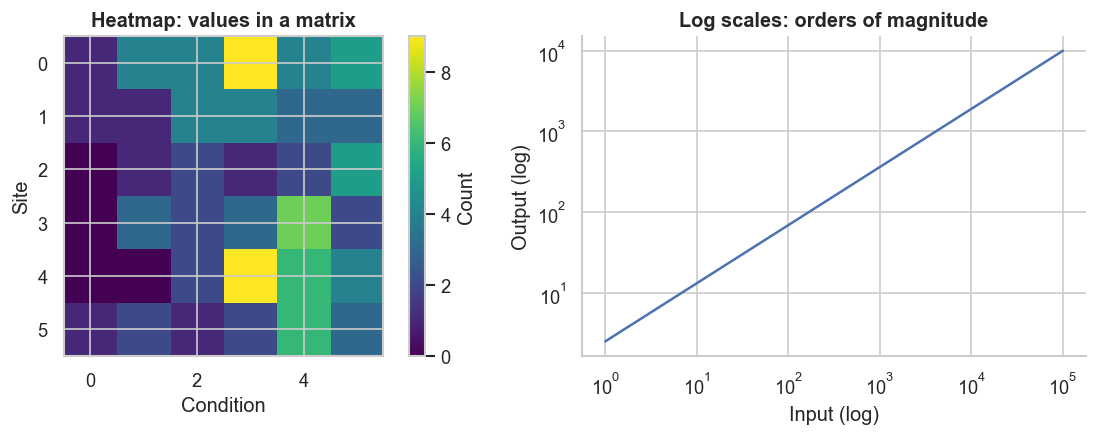

In [12]:
matrix = rng.poisson(lam=np.arange(1, 7), size=(6, 6))
scale_x = np.logspace(0, 5, 80)
scale_y = 2.5 * scale_x ** .72
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
im = axes[0].imshow(matrix, cmap="viridis")
axes[0].set(title="Heatmap: values in a matrix", xlabel="Condition", ylabel="Site")
fig.colorbar(im, ax=axes[0], label="Count")
axes[1].plot(scale_x, scale_y)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set(title="Log scales: orders of magnitude", xlabel="Input (log)", ylabel="Output (log)")
axes[1].spines[["top","right"]].set_visible(False)
fig.tight_layout(); plt.show()

## 3. Interaction ต้องมีงานให้ทำ

Interaction ที่ดีตอบว่า “ผู้ใช้จะค้นหาอะไรที่ภาพนิ่งทำได้ยาก?” เช่น

- hover เพื่ออ่าน observation เฉพาะจุด
- zoom/filter เพื่อสำรวจช่วงหรือ subgroup
- brush เพื่อเชื่อม observation เดียวกันข้ามหลายมุมมอง

ถ้าไม่มี task เหล่านี้ ภาพนิ่งที่ออกแบบดีมักส่งต่อ เก็บถาวร และอ้างใน paper ง่ายกว่า
`[DV-EBOOK, pdf pp. 18–19]`; `[HANDBOOK, pdf pp. 229–247]`

### Plotly — hover เพื่อกลับไปหา observation

ตัวอย่างนี้แบ่งวิธีเป็นสาม panel และเก็บ run, humidity, เวลา และ error ไว้ใน tooltip เป้าหมายของ
interaction คือระบุจุดผิดปกติและย้อนกลับไปดู run ที่เกี่ยวข้อง ไม่ใช่เพียงทำให้จุดขยับได้

> **ที่มาหลัก:** หลัก overview/filter/details จาก `[DV-EBOOK, pdf pp. 18–19]`; linked exploration จาก `[HANDBOOK, pdf pp. 211–247]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

In [13]:
interactive_sample = sensor_df.query("run <= 6").copy()
fig = px.scatter(
    interactive_sample,
    x="minute", y="error_ppm", color="method", facet_col="method",
    hover_data={"run": True, "humidity": ":.1f", "minute": True, "error_ppm": ":.2f"},
    category_orders={"method": methods},
    color_discrete_map=palette,
    title="Plotly: hover identifies the run behind an unusual point",
    labels={"minute": "Minutes", "error_ppm": "Absolute error (ppm)"},
)
fig.update_layout(height=430, showlegend=False)
fig.show()

### Altair — brushing เชื่อมสองมุมมอง

ลากกรอบเลือกจุดใน scatterplot แล้ว histogram ด้านล่างจะคำนวณใหม่จาก observation ที่เลือก
linked views เหมาะเมื่อเราต้องการรู้ว่า subgroup ในมุมมองหนึ่งมี distribution อย่างไรในอีกมุมมอง

> **ที่มาหลัก:** `[HANDBOOK, pdf pp. 211–247]`; `[DV-EBOOK, pdf pp. 18–19]` ตัวอย่างและข้อมูลใน notebook สร้างใหม่เพื่อการสอน

In [14]:
# Altair linked views: brush points in the scatterplot to update the humidity distribution.
linked = sensor_df.query("minute in [15, 30, 45] and run <= 12").copy()
brush = alt.selection_interval(encodings=["x", "y"], name="brush")

scatter = (
    alt.Chart(linked)
    .mark_circle(size=65, opacity=.72)
    .encode(
        x=alt.X("humidity:Q", title="Humidity (%)"),
        y=alt.Y("error_ppm:Q", title="Absolute error (ppm)"),
        color=alt.condition(brush, "method:N", alt.value("#D5D5D5")),
        tooltip=["method:N", "run:O", "minute:Q", alt.Tooltip("humidity:Q", format=".1f"),
                 alt.Tooltip("error_ppm:Q", format=".2f")],
    )
    .add_params(brush)
    .properties(width=470, height=280, title="Drag a rectangle to select observations")
)

hist = (
    alt.Chart(linked)
    .mark_bar()
    .encode(
        x=alt.X("humidity:Q", bin=alt.Bin(maxbins=18), title="Humidity (%)"),
        y=alt.Y("count():Q", title="Selected observations"),
        color=alt.Color("method:N", legend=alt.Legend(orient="bottom")),
    )
    .transform_filter(brush)
    .properties(width=470, height=130)
)
(scatter & hist).resolve_scale(color="shared")

alt.VConcatChart(...)

---

Prompt, Chart Contract, ขั้นตอน Graph Clinic, แบบนำข้อมูลตนเองมาใช้ และเกณฑ์ส่งงานอยู่ใน
[Module 7 Workflow & Prompt Card](../templates/module-07-visualization-workflow-and-prompts.md)